# 04b — Behavioural predictors (fixed-horizon onboarding design)

Do first-month behaviours predict churn within 12 months? Population: paid
companies with first paid subscription in 2024-02..2025-05 (events logging
starts 2024-01, so every company has full 30-day coverage; 12-month outcome is
observable for all). Features: events/tickets/seats in days [fp, fp+30).
Labels: `churned_12mo` (no live paid sub at fp+365d AND a paid cancel before
then) vs `retained` (live paid sub at fp+365d). 18 ambiguous horizon states
excluded. M2/M3 definitions reused (paid = tier != free; live = start < bound
AND (cancelled_at IS NULL OR >= bound), billable standing only).

Why not a calendar window (churned in Dec–Feb vs retained)? Most churners are
young (M3's month-1 cliff) — requiring 90 days of pre-window exposure shrinks
the churned set to n=13 and selects only old churners. The onboarding design
fixes exposure by construction and directly tests M3's cliff.

**Run:** `export SAAS_DSN='<read-only postgres DSN>'`, then run all cells.

In [1]:
import os

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2
import seaborn as sns

warnings.filterwarnings("ignore")

dsn = os.environ.get("SAAS_DSN")
assert dsn, "Set SAAS_DSN to the read-only Postgres DSN before running."
conn = psycopg2.connect(dsn)

FP_START, FP_END, OBS_DAYS, HORIZON_DAYS = "2024-02-01", "2025-06-01", 30, 365

In [2]:
POP_SQL = '''
WITH first_paid AS (
    SELECT account_id, MIN(start_date) AS fp
    FROM saas.subscriptions
    WHERE LOWER(plan) <> 'free' AND status <> 'trialing'
    GROUP BY 1
),
pop AS (
    SELECT account_id, fp FROM first_paid
    WHERE fp >= %(fp_start)s::date AND fp < %(fp_end)s::date
)
SELECT p.account_id, p.fp,
       CASE WHEN EXISTS (
                 SELECT 1 FROM saas.subscriptions s
                 WHERE s.account_id = p.account_id AND LOWER(s.plan) <> 'free'
                   AND s.status IN ('active', 'past_due')
                   AND s.start_date < p.fp + interval '365 days'
                   AND (s.cancelled_at IS NULL
                        OR s.cancelled_at >= p.fp + interval '365 days'))
            THEN 'retained'
            WHEN EXISTS (
                 SELECT 1 FROM saas.subscriptions s
                 WHERE s.account_id = p.account_id AND LOWER(s.plan) <> 'free'
                   AND s.status = 'churned'
                   AND s.cancelled_at <= p.fp + interval '365 days')
            THEN 'churned_12mo' ELSE 'ambiguous' END AS label
FROM pop p'''
pop = pd.read_sql(POP_SQL, conn,
                  params={"fp_start": FP_START, "fp_end": FP_END})
pop["fp"] = pd.to_datetime(pop["fp"])
print(pop.label.value_counts().to_dict())
assert (pop.label == "churned_12mo").sum() == 71
assert (pop.label == "retained").sum() == 231

{'retained': 231, 'churned_12mo': 71, 'ambiguous': 18}


In [3]:
EV_SQL = '''
SELECT e.account_id, e.event_type,
       (e.occurred_at::date - f.fp::date) AS day_offset
FROM saas.events e JOIN (%s) f USING (account_id)
WHERE e.occurred_at >= f.fp AND e.occurred_at < f.fp + interval '30 days'
''' % POP_SQL.replace("%(fp_start)s", "'" + FP_START + "'").replace(
    "%(fp_end)s", "'" + FP_END + "'")
ev = pd.read_sql(EV_SQL, conn)
ev["day_offset"] = ev["day_offset"].astype(int)

TIX_SQL = '''
SELECT t.account_id, t.category
FROM saas.support_tickets t JOIN (%s) f USING (account_id)
WHERE t.opened_at >= f.fp::timestamptz
  AND t.opened_at < f.fp::timestamptz + interval '30 days'
''' % POP_SQL.replace("%(fp_start)s", "'" + FP_START + "'").replace(
    "%(fp_end)s", "'" + FP_END + "'")
tix = pd.read_sql(TIX_SQL, conn)

SEAT_SQL = '''
SELECT st.account_id, COUNT(*) AS n_seats
FROM saas.seats st JOIN (%s) f USING (account_id)
WHERE st.activated_at >= f.fp::timestamptz
  AND st.activated_at < f.fp::timestamptz + interval '30 days'
GROUP BY 1
''' % POP_SQL.replace("%(fp_start)s", "'" + FP_START + "'").replace(
    "%(fp_end)s", "'" + FP_END + "'")
seats = pd.read_sql(SEAT_SQL, conn)
print("events:", len(ev), "| tickets:", len(tix), "| seat rows:", len(seats))

events: 573 | tickets: 21 | seat rows: 40


In [4]:
lab = pop[pop.label != "ambiguous"].copy()
g = ev.groupby("account_id")
feat = pd.DataFrame({"account_id": lab.account_id.values})
feat = feat.merge(lab[["account_id", "label"]], on="account_id")
feat["n_events"] = feat.account_id.map(g.size()).fillna(0).astype(int)
feat["n_days"] = feat.account_id.map(
    g.apply(lambda d: d["day_offset"].nunique(), include_groups=False)).fillna(0).astype(int)
feat["n_types"] = feat.account_id.map(
    g.apply(lambda d: d["event_type"].nunique(), include_groups=False)).fillna(0).astype(int)
feat["wk1"] = feat.account_id.map(
    g.apply(lambda d: (d["day_offset"] < 7).sum(), include_groups=False)).fillna(0).astype(int)
feat["wk4"] = feat.account_id.map(
    g.apply(lambda d: (d["day_offset"] >= 21).sum(), include_groups=False)).fillna(0).astype(int)
feat["eval_burst"] = feat.account_id.map(
    g.apply(lambda d: d["event_type"].isin(["dashboard_view", "export"]).any(),
            include_groups=False)).fillna(False).astype(bool)
feat["invited"] = feat.account_id.map(
    g.apply(lambda d: (d["event_type"] == "invite_sent").any(),
            include_groups=False)).fillna(False).astype(bool)
feat["n_tickets"] = feat.account_id.map(
    tix.groupby("account_id").size()).fillna(0).astype(int)
feat["n_seats"] = feat.account_id.map(
    seats.set_index("account_id")["n_seats"]).fillna(0).astype(int)

def gap(a, b):
    return (a - b) / b if b else float("nan")

rows = []
for col, fmt in [("n_events", "mean"), ("n_days", "mean"), ("n_types", "mean"),
                 ("n_tickets", "mean"), ("n_seats", "mean")]:
    m = feat.groupby("label")[col].mean()
    rows.append((col, m["churned_12mo"], m["retained"], gap(m["churned_12mo"], m["retained"])))
for col in ["eval_burst", "invited"]:
    m = feat.groupby("label")[col].mean()
    rows.append((col + " (penetration)", m["churned_12mo"], m["retained"],
                 gap(m["churned_12mo"], m["retained"])))
rows.append(("zero_events (penetration)",
             (feat[feat.label == "churned_12mo"].n_events == 0).mean(),
             (feat[feat.label == "retained"].n_events == 0).mean(), np.nan))
comp = pd.DataFrame(rows, columns=["feature", "churned", "retained", "rel_gap"])
print(comp.to_string(index=False))
seg = feat.assign(
    segment=np.where(feat.invited, "invited",
                     np.where(feat.eval_burst, "eval-burst, no invite", "quiet")))
print(seg.groupby("segment").agg(n=("label", "size"),
      churn_rate=("label", lambda s: (s == "churned_12mo").mean())).round(3))

                  feature  churned  retained   rel_gap
                 n_events 3.478873  1.376623  1.527106
                   n_days 2.422535  1.233766  0.963529
                  n_types 1.380282  0.891775  0.547792
                n_tickets 0.183099  0.034632  4.286972
                  n_seats 0.253521  0.303030 -0.163380
 eval_burst (penetration) 0.352113  0.186147  0.891582
    invited (penetration) 0.070423  0.082251 -0.143810
zero_events (penetration) 0.478873  0.523810       NaN
                         n  churn_rate
segment                               
eval-burst, no invite   58       0.362
invited                 24       0.208
quiet                  220       0.205


saved: /home/anuj/Personal/Saas-CHurn-Akshobya\]/figures/predictor_comparison.png


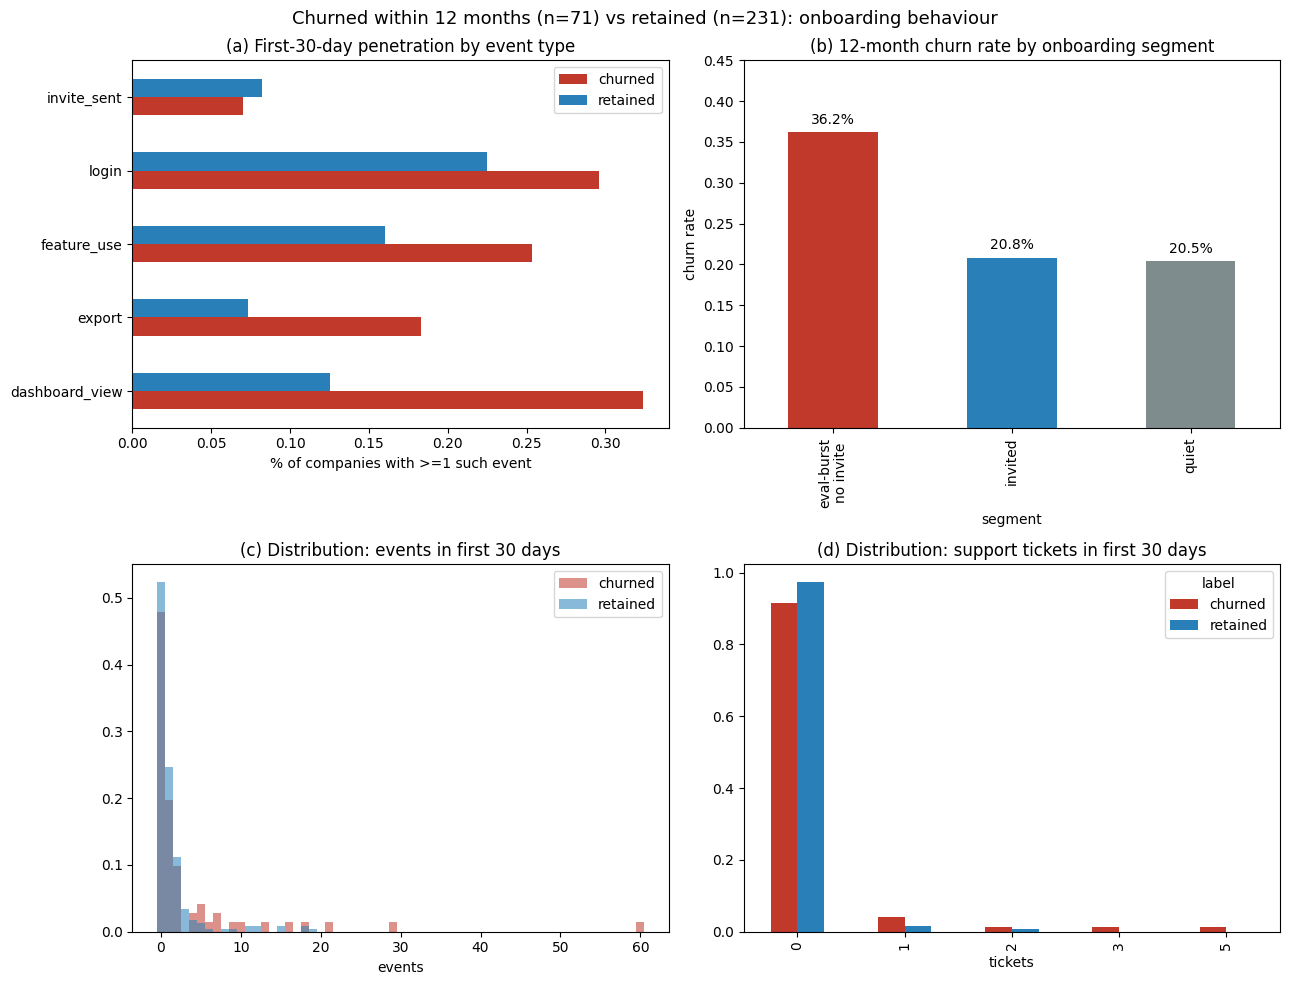

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

types = ["dashboard_view", "export", "feature_use", "login", "invite_sent"]
type_accts = ev.groupby("event_type").account_id.unique()
pen = pd.DataFrame(
    {t: {lab: feat[feat.label == lab].account_id
         .isin(type_accts.get(t, [])).mean()
         for lab in ["churned_12mo", "retained"]} for t in types}).T
pen = pen.rename(columns={"churned_12mo": "churned"})
pen[["churned", "retained"]].plot.barh(ax=ax[0, 0], color=["#c0392b", "#2980b9"])
ax[0, 0].set_title("(a) First-30-day penetration by event type")
ax[0, 0].set_xlabel("% of companies with >=1 such event")

s = feat.assign(
    segment=np.where(feat.invited, "invited",
                     np.where(feat.eval_burst, "eval-burst\nno invite", "quiet")))
rate = s.groupby("segment").label.apply(lambda x: (x == "churned_12mo").mean())
rate = rate.reindex(["eval-burst\nno invite", "invited", "quiet"])
rate.plot.bar(ax=ax[0, 1], color=["#c0392b", "#2980b9", "#7f8c8d"])
ax[0, 1].set_title("(b) 12-month churn rate by onboarding segment")
ax[0, 1].set_ylabel("churn rate")
ax[0, 1].set_ylim(0, 0.45)
for i, v in enumerate(rate.values):
    ax[0, 1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=10)

mx = int(feat.n_events.max())
bins = np.arange(0, mx + 2) - 0.5
for lbl, col, disp in [("churned_12mo", "#c0392b", "churned"),
                       ("retained", "#2980b9", "retained")]:
    vals = feat[feat.label == lbl].n_events.values
    ax[1, 0].hist(vals, bins=bins, alpha=0.55, label=disp, color=col, density=True)
ax[1, 0].set_title("(c) Distribution: events in first 30 days")
ax[1, 0].set_xlabel("events")
ax[1, 0].legend()

tb = feat.groupby(["label", "n_tickets"]).size().unstack(fill_value=0)
tb = tb.div(tb.sum(axis=1), axis=0)
tb.index = tb.index.map({"churned_12mo": "churned", "retained": "retained"})
tb.T.plot.bar(ax=ax[1, 1], color=["#c0392b", "#2980b9"])
ax[1, 1].set_title("(d) Distribution: support tickets in first 30 days")
ax[1, 1].set_xlabel("tickets")

plt.suptitle("Churned within 12 months (n=71) vs retained (n=231): onboarding behaviour",
             fontsize=13)
plt.tight_layout()
import os as _os
out = _os.path.join(_os.path.abspath(_os.path.join(_os.getcwd(), "..")),
                    "figures", "predictor_comparison.png")
plt.savefig(out, dpi=150)
print("saved:", out)

In [6]:
print("MOST IMPORTANT: eval-burst without invite ->",
      f"{(seg[seg.segment == 'eval-burst, no invite'].label == 'churned_12mo').mean():.1%} churn",
      f"(n={(seg.segment == 'eval-burst, no invite').sum()}) vs baseline",
      f"{(feat.label == 'churned_12mo').mean():.1%}")
print(tix.merge(lab[["account_id", "label"]], on="account_id")
      .groupby(["label", "category"]).size().to_string())
conn.close()

MOST IMPORTANT: eval-burst without invite -> 36.2% churn (n=58) vs baseline 23.5%
label         category       
churned_12mo  billing            3
              bug_report         3
              feature_request    3
              onboarding         1
              technical          3
retained      billing            2
              bug_report         1
              feature_request    1
              onboarding         1
              technical          3
